# Aircraft Engine RUL Prediction

## Load the training data and separate it by engine

In [1]:
import pandas as pd

df = pd.read_csv("TrainingData_Engine.csv", encoding="utf-8")
df["RUL"] = df.groupby("EngineID")["Cycle"].transform("max") - df["Cycle"]

# One DataFrame per engine: engines[1] ... engines[260]
engines = {engine_id: g.reset_index(drop=True) for engine_id, g in df.groupby("EngineID")}

assert sorted(engines) == list(range(1, 261))
assert sum(len(g) for g in engines.values()) == len(df)

life = pd.Series({engine_id: len(g) for engine_id, g in engines.items()}, name="flights")
print(f"{len(df):,} flights x {df.shape[1]} columns across {len(engines)} engines")
print(f"Engine life: min {life.min()}, median {life.median():.0f}, max {life.max()} flights")
engines[1].head()

53,759 flights x 28 columns across 260 engines
Engine life: min 128, median 199, max 378 flights


,EngineID,Cycle,Regime,Altitude,Mach #,Power Setting (TRA),T2 Total temperature at fan inlet °R,T24 Total temperature at LPC outlet °R,T30 Total temperature at HPC outlet °R,T50 Total temperature at LPT outlet °R,...,NRf Corrected fan speed rpm,NRc Corrected core speed rpm,BPR Bypass Ratio --,farB Burner fuel-air ratio --,htBleed (Bleed Enthalpy),Nf_dmd Demanded fan speed rpm,PCNfR_dmd Demanded corrected fan speed rpm,W31 HPT coolant bleed lbm/s,W32 LPT coolant bleed lbm/s,RUL
0,1,1,5,34.9983,0.8400,100,449.44,555.32,1358.61,1137.23,...,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071,148
1,1,2,6,41.9982,0.8408,100,445.00,549.90,1353.22,1125.78,...,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665,147
2,1,3,4,24.9988,0.6218,60,462.54,537.31,1256.76,1047.45,...,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723,146
3,1,4,6,42.0077,0.8416,100,445.00,549.51,1354.03,1126.38,...,2387.61,8068.66,9.3528,0.02,329,2212,100.00,10.59,6.4701,145
4,1,5,4,25.0005,0.6203,60,462.54,537.07,1257.71,1047.93,...,2028.00,7861.23,10.8963,0.02,309,1915,84.93,14.13,8.5286,144


## Prepare the data for visualization

Sensor readings are dominated by flight regime, so each sensor is z-scored within its regime against a healthy baseline: the first 30 flights of every training engine. `normalize` takes that baseline as an argument, so the test engines can reuse it unchanged.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator, PercentFormatter
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA

SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, ENGINE_LINE = "#e1e0d9", "#c3c2b7", "#b5b4ad"
BLUE, ORANGE = "#2a78d6", "#eb6834"
REGIME_COLORS = dict(zip(range(1, 7), ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 10.5, "axes.titlelocation": "left", "axes.titleweight": "semibold",
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False,
})

In [3]:
HEALTHY_FLIGHTS = 30  # first flights of each engine, assumed healthy
LATE_FLIGHTS = 30     # last flights of each engine, treated as degraded
SMOOTH_FLIGHTS = 15   # trailing window for smoothed trends

names = {c: c.split()[0] for c in df.columns[6:] if c != "RUL"}
sensors = list(names.values())
data = df.rename(columns=names)

baseline = data[data["Cycle"] <= HEALTHY_FLIGHTS].groupby("Regime")[sensors].agg(["mean", "std"])

def normalize(frame, baseline):
    """Z-score each sensor within its regime; sensors flat within a regime become 0."""
    mean = baseline.xs("mean", axis=1, level=1).reindex(frame["Regime"]).to_numpy()
    std = baseline.xs("std", axis=1, level=1).reindex(frame["Regime"]).to_numpy()
    z = (frame[sensors].to_numpy() - mean) / np.where(std > 1e-9, std, np.inf)
    return pd.concat([frame.drop(columns=sensors), pd.DataFrame(z, columns=sensors, index=frame.index)], axis=1)

def smooth(frame, columns):
    """Trailing per-engine mean; NaN until a full window is available."""
    rolled = frame.groupby("EngineID")[columns].rolling(SMOOTH_FLIGHTS).mean()
    return rolled.reset_index(level=0, drop=True).sort_index()

z = normalize(data, baseline)
z_smooth = smooth(z, sensors)

# Fisher criterion: healthy flights vs. each engine's last flights
healthy, late = z[z["Cycle"] <= HEALTHY_FLIGHTS], z[z["RUL"] < LATE_FLIGHTS]
fisher = ((late[sensors].mean() - healthy[sensors].mean()) ** 2
          / (late[sensors].var() + healthy[sensors].var())).fillna(0).sort_values(ascending=False)

active = [s for s in fisher.index if z[s].std() > 0]    # varies within a regime
speeds = ["Nf", "NRf", "Nc", "NRc"]
selected = [s for s in fisher.index[fisher >= 2] if s not in speeds]

print(f"Flat within every regime: {[s for s in sensors if s not in active]}")
print(f"Selected for PCA (Fisher >= 2): {selected}")

Flat within every regime: ['T2', 'P2', 'Nf_dmd', 'PCNfR_dmd']
Selected for PCA (Fisher >= 2): ['Ps30', 'T50', 'BPR', 'htBleed', 'T24', 'T30']


## 1. Engine life, training vs. test

Test engines are still in service, so their flight counts are a lower bound on life. Look at how far along they are compared with complete training lives.

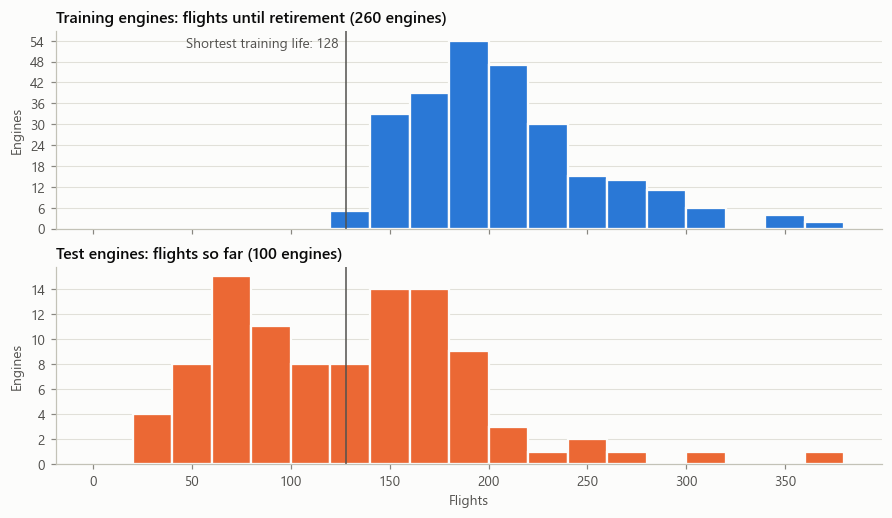

Test engines already past the shortest training life: 49 of 100
Test engines past the median training life: 9 of 100


In [4]:
test = sio.loadmat("Testing_DataSet/TestingData_Engine.mat", squeeze_me=True, struct_as_record=False)
test_flights = pd.Series([run.Data.shape[0] for run in test["Testing_EngineRun"]], name="flights")

bins = np.arange(0, 400, 20)
fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True, layout="constrained")
for ax, values, color, title in [
    (axes[0], life, BLUE, "Training engines: flights until retirement (260 engines)"),
    (axes[1], test_flights, ORANGE, "Test engines: flights so far (100 engines)"),
]:
    ax.hist(values, bins=bins, color=color, edgecolor=SURFACE, linewidth=1.5)
    ax.axvline(life.min(), color=INK_2, linewidth=1)
    ax.set_title(title)
    ax.set_ylabel("Engines")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="x", visible=False)
axes[0].annotate(f"Shortest training life: {life.min()}", (life.min(), 1), xycoords=("data", "axes fraction"),
                 xytext=(-5, -4), textcoords="offset points", ha="right", va="top", color=INK_2)
axes[1].set_xlabel("Flights")
plt.show()

print(f"Test engines already past the shortest training life: {(test_flights > life.min()).sum()} of {len(test_flights)}")
print(f"Test engines past the median training life: {(test_flights > life.median()).sum()} of {len(test_flights)}")

## 2. Why raw sensors need normalizing

Consecutive flights jump between regimes, so one engine's raw trace is a sawtooth. The regime bands are far wider apart than any wear trend, and the altitude/Mach plot confirms the six regimes are tight clusters.

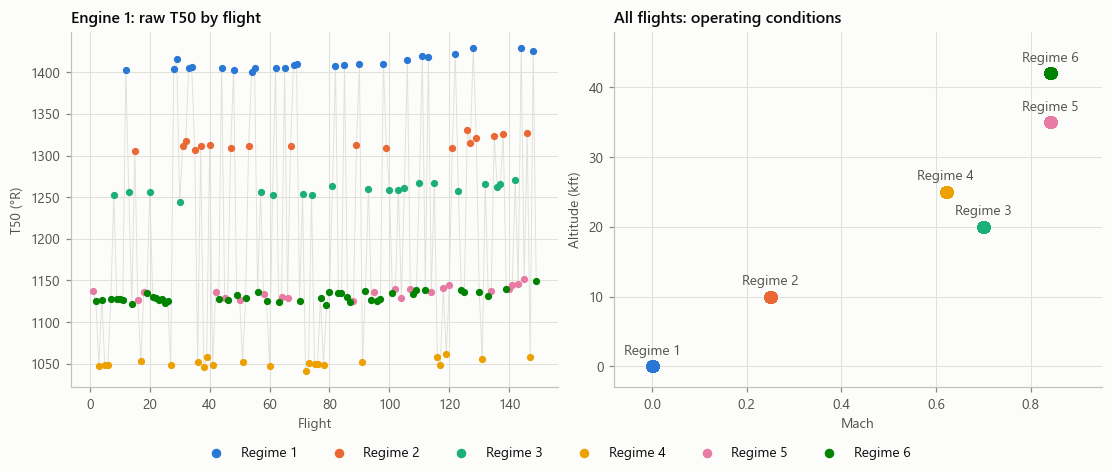

Median share of sensor variance explained by regime: 100.0%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")

ax = axes[0]
one = data[data["EngineID"] == 1]
ax.plot(one["Cycle"], one["T50"], color=GRID, linewidth=0.6, zorder=1)
for regime, color in REGIME_COLORS.items():
    flights = one[one["Regime"] == regime]
    ax.scatter(flights["Cycle"], flights["T50"], s=14, color=color, label=f"Regime {regime}", zorder=2)
ax.set(title="Engine 1: raw T50 by flight", xlabel="Flight", ylabel="T50 (°R)")

ax = axes[1]
for regime, color in REGIME_COLORS.items():
    flights = data[data["Regime"] == regime]
    ax.scatter(flights["Mach #"], flights["Altitude"], s=46, color=color)
    ax.annotate(f"Regime {regime}", (flights["Mach #"].mean(), flights["Altitude"].mean()),
                xytext=(0, 8), textcoords="offset points", ha="center", color=INK_2)
ax.set(title="All flights: operating conditions", xlabel="Mach", ylabel="Altitude (kft)", xlim=(-0.08, 0.95), ylim=(-3, 48))

fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncols=6, markerscale=1.4)
plt.show()

raw_var = data[sensors].var()
within_var = (data[sensors] - data.groupby("Regime")[sensors].transform("mean")).var()
print(f"Median share of sensor variance explained by regime: {(1 - within_var / raw_var).median():.1%}")

## 3. Normalized sensors approaching retirement

Each grey line is one engine, smoothed over 15 flights and aligned at retirement (flight 0). The blue line is the fleet median, and the band is the middle 50% of engines. Panels are ordered by Fisher score. Sensors worth keeping leave zero steadily and stay in a tight band. The y-axis is cut at ±8 so panels stay comparable, which clips some late `Nf`, `NRf`, `Nc`, `NRc` and `epr` lines.

The table below checks the healthy-baseline assumption: medians should stay near 0 in the first 30 flights and drift only afterwards.

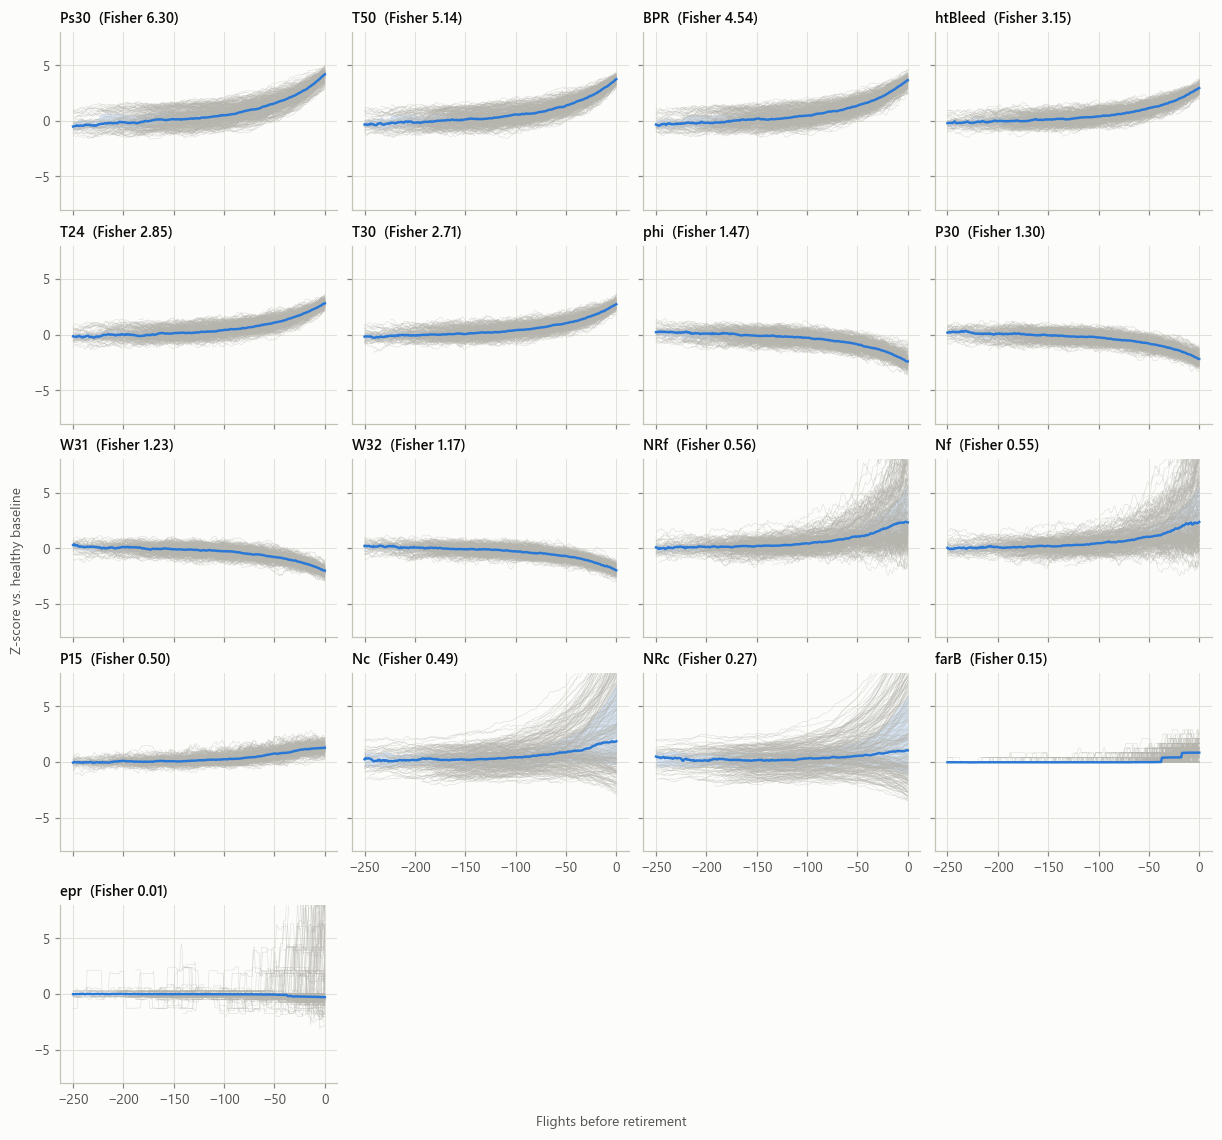

,Ps30,T50,BPR,htBleed,T24,T30
Flights,,,,,,
"(0, 30]",-0.04,-0.02,-0.01,-0.19,-0.01,-0.01
"(30, 60]",0.10,0.11,0.09,0.20,0.10,0.10
"(60, 90]",0.35,0.31,0.32,0.35,0.26,0.26
"(90, 120]",0.79,0.71,0.71,0.54,0.56,0.52


In [6]:
cols = 4
rows = -(-len(active) // cols)
fig, axes = plt.subplots(rows, cols, figsize=(11, 2.05 * rows), sharex=True, sharey=True, layout="constrained")

for ax, sensor in zip(axes.flat, active):
    wide = (pd.DataFrame({"RUL": z["RUL"], "EngineID": z["EngineID"], "value": z_smooth[sensor]})
            .pivot(index="RUL", columns="EngineID", values="value").loc[:250])
    ax.plot(-wide.index, wide.to_numpy(), color=ENGINE_LINE, linewidth=0.35, alpha=0.45)
    ax.fill_between(-wide.index, wide.quantile(0.25, axis=1), wide.quantile(0.75, axis=1), color=BLUE, alpha=0.18, linewidth=0)
    ax.plot(-wide.index, wide.median(axis=1), color=BLUE, linewidth=1.6)
    ax.set_title(f"{sensor}  (Fisher {fisher[sensor]:.2f})", fontsize=9.5)
    ax.set_ylim(-8, 8)
for ax in axes.flat[len(active):]:
    ax.set_visible(False)
for ax in axes.flat[len(active) - cols:len(active)]:
    ax.tick_params(labelbottom=True)
fig.supxlabel("Flights before retirement", color=INK_2, fontsize=9)
fig.supylabel("Z-score vs. healthy baseline", color=INK_2, fontsize=9)
plt.show()

# Baseline check: a healthy window should sit near 0, with drift only arriving later
early = z.groupby(pd.cut(z["Cycle"], [0, 30, 60, 90, 120]), observed=True)[selected].median().round(2)
early.index.name = "Flights"
display(early)

## 4. Fisher score by sensor

Separation between each engine's first and last 30 flights. Blue sensors feed the PCA below. The speed sensors are excluded whatever their score, for the reason shown in plot 5.

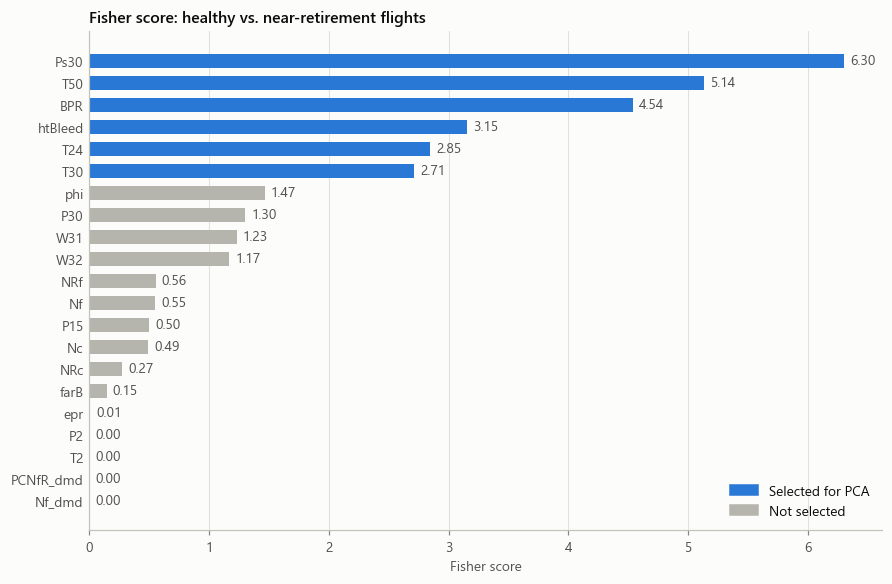

In [7]:
ranked = fisher.sort_values()
fig, ax = plt.subplots(figsize=(8, 5.2), layout="constrained")
colors = [BLUE if s in selected else ENGINE_LINE for s in ranked.index]
bars = ax.barh(ranked.index, ranked, color=colors, height=0.62)
ax.bar_label(bars, labels=[f"{v:.2f}" for v in ranked], padding=4, color=INK_2)
ax.set(title="Fisher score: healthy vs. near-retirement flights", xlabel="Fisher score")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ENGINE_LINE)],
          labels=["Selected for PCA", "Not selected"], loc="lower right")
plt.show()

## 5. Does each sensor trend the same way on every engine?

Each box shows the per-engine Spearman correlation between a sensor and flight number. A narrow box far from zero is a consistent degradation signal. A wide box that crosses zero means the sensor rises on some engines and falls on others.

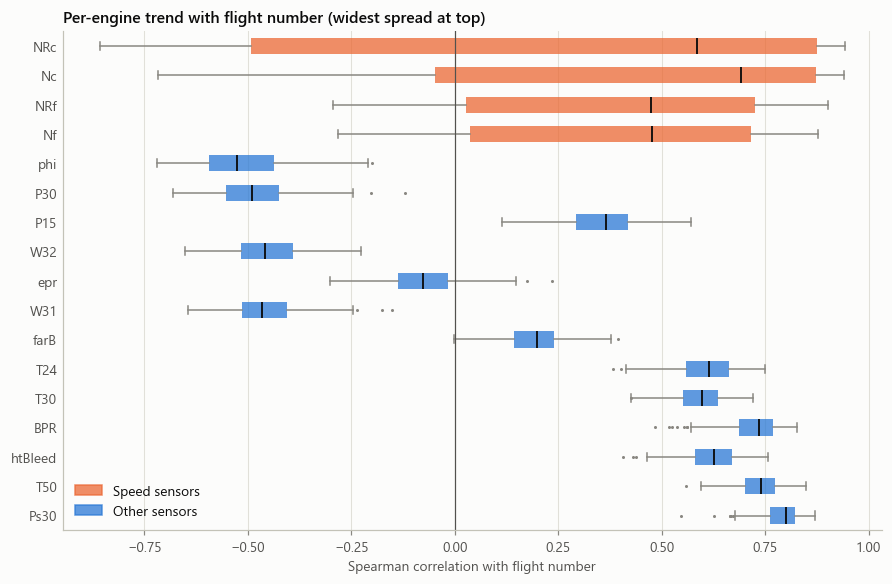

,rising (rho > 0.3),falling (rho < -0.3)
Nf,0.58,0.00
NRf,0.58,0.00
Nc,0.63,0.17
NRc,0.57,0.32


In [8]:
trend = pd.DataFrame({engine_id: g[active].corrwith(g["Cycle"], method="spearman")
                      for engine_id, g in z.groupby("EngineID")}).T
order = trend.std().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(8, 5.2), layout="constrained")
boxes = ax.boxplot([trend[s].dropna() for s in order], vert=False, tick_labels=list(order), widths=0.55, patch_artist=True,
                   medianprops={"color": INK, "linewidth": 1.2}, whiskerprops={"color": MUTED}, capprops={"color": MUTED},
                   flierprops={"marker": "o", "markersize": 2, "markerfacecolor": MUTED, "markeredgecolor": "none"})
for box, sensor in zip(boxes["boxes"], order):
    box.set(facecolor=ORANGE if sensor in speeds else BLUE, edgecolor="none", alpha=0.75)
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set(title="Per-engine trend with flight number (widest spread at top)", xlabel="Spearman correlation with flight number")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE, alpha=0.75), plt.Rectangle((0, 0), 1, 1, color=BLUE, alpha=0.75)],
          labels=["Speed sensors", "Other sensors"], loc="lower left")
plt.show()

display(pd.DataFrame({"rising (rho > 0.3)": (trend[speeds] > 0.3).mean(),
                      "falling (rho < -0.3)": (trend[speeds] < -0.3).mean()}).round(2))

## 6. Sensor redundancy

Correlation of the normalized sensors, reordered so that related sensors sit together. Only pairs at |r| of 0.9 or more are labeled, because those carry nearly the same information.

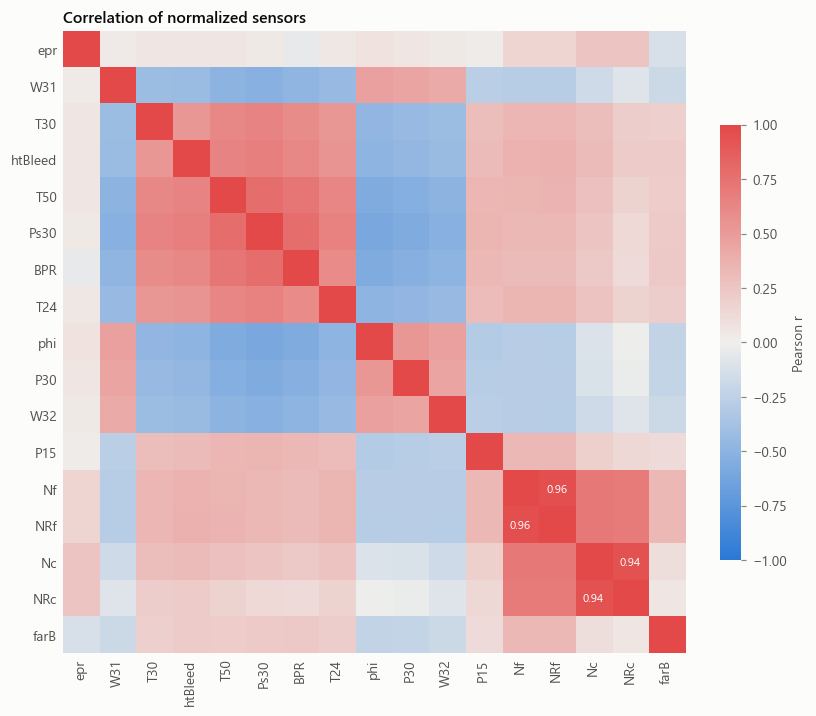

In [9]:
corr = z[active].corr()
distance = squareform(1 - corr.abs().to_numpy(), checks=False)
order = corr.index[leaves_list(linkage(distance, method="average", optimal_ordering=True))]
corr = corr.loc[order, order]

diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(7.6, 6.4), layout="constrained")
image = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=90)
ax.set_yticks(range(len(order)), order)
ax.grid(False)
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.set_title("Correlation of normalized sensors")
for i in range(len(order)):
    for j in range(len(order)):
        if i != j and abs(corr.iloc[i, j]) >= 0.9:
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="white", fontsize=7.5)
fig.colorbar(image, ax=ax, shrink=0.7, label="Pearson r").outline.set_visible(False)
plt.show()

## 7. PCA before and after normalization

The scree plot shows how many components matter. The scatters color each flight by RUL: on raw data PCA finds the regimes, while on normalized data RUL should change steadily along PC1. Single flights are noisy, so expect a gradient across a cloud rather than a thin path.

PCA is fit on the training engines only, so `pca` can be applied to the test set as it stands.

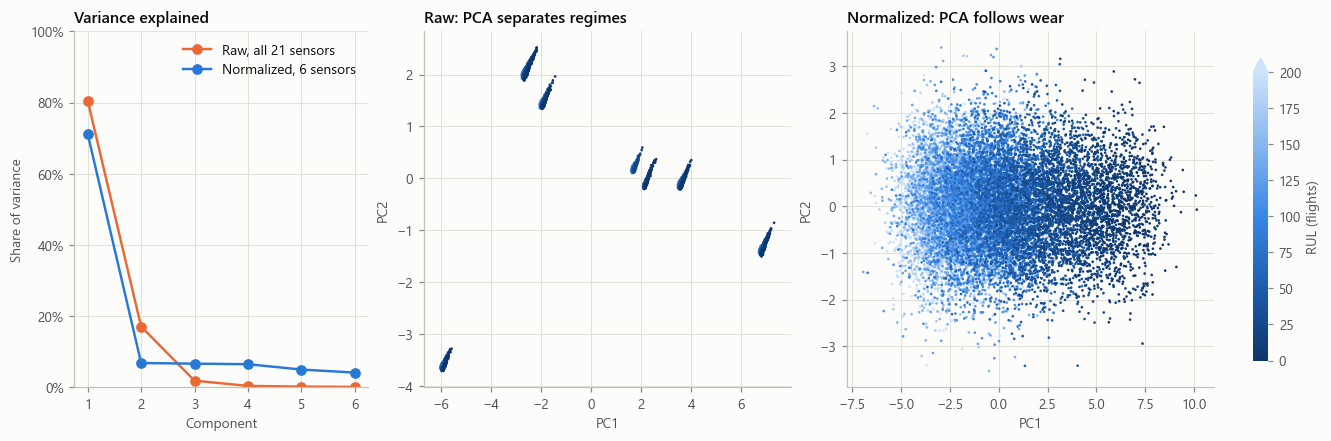

Raw PC1: 80.4% of variance, 99.9% of it explained by regime, Spearman with RUL -0.12
Normalized PC1: 71.1% of variance, Spearman with RUL -0.77


,PC1 loading
Ps30,0.50
T50,0.45
BPR,0.44
htBleed,0.36
T24,0.35
T30,0.33


In [10]:
raw_scaled = (data[sensors] - data[sensors].mean()) / data[sensors].std()
pca_raw = PCA().fit(raw_scaled)
raw_scores = pca_raw.transform(raw_scaled)

pca = PCA().fit(z[selected])
scores = pca.transform(z[selected])
if np.corrcoef(scores[:, 0], z["RUL"])[0, 1] > 0:   # orient PC1 so higher means more degraded
    pca.components_[0] *= -1
    scores[:, 0] *= -1

rul_map = LinearSegmentedColormap.from_list("rul", ["#0d366b", "#1c5cab", "#3987e5", "#86b6ef", "#cde2fb"])
sample = z.sample(15000, random_state=0).sort_values("RUL", ascending=False).index

fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), layout="constrained", width_ratios=[0.8, 1, 1])
ax = axes[0]
n = np.arange(1, 7)
ax.plot(n, pca_raw.explained_variance_ratio_[:6], color=ORANGE, marker="o", linewidth=1.6, label="Raw, all 21 sensors")
ax.plot(n, pca.explained_variance_ratio_[:6], color=BLUE, marker="o", linewidth=1.6, label=f"Normalized, {len(selected)} sensors")
ax.set(title="Variance explained", xlabel="Component", ylabel="Share of variance", ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc="upper right")

for ax, values, title in [(axes[1], raw_scores, "Raw: PCA separates regimes"), (axes[2], scores, "Normalized: PCA follows wear")]:
    points = ax.scatter(values[sample, 0], values[sample, 1], c=z.loc[sample, "RUL"], cmap=rul_map, vmin=0, vmax=200, s=3, linewidths=0)
    ax.set(title=title, xlabel="PC1", ylabel="PC2")
fig.colorbar(points, ax=axes[1:], label="RUL (flights)", extend="max", shrink=0.85).outline.set_visible(False)
plt.show()

regime_share = 1 - pd.Series(raw_scores[:, 0]).groupby(z["Regime"]).transform(lambda v: v - v.mean()).var() / raw_scores[:, 0].var()
print(f"Raw PC1: {pca_raw.explained_variance_ratio_[0]:.1%} of variance, {regime_share:.1%} of it explained by regime, "
      f"Spearman with RUL {pd.Series(raw_scores[:, 0]).corr(z['RUL'], method='spearman'):+.2f}")
print(f"Normalized PC1: {pca.explained_variance_ratio_[0]:.1%} of variance, "
      f"Spearman with RUL {pd.Series(scores[:, 0]).corr(z['RUL'], method='spearman'):+.2f}")
display(pd.Series(pca.components_[0], index=selected, name="PC1 loading").round(2).to_frame())

## 8. PC1 as a health indicator

This is the same view as Figure 1 of the project brief. If engines follow a shared path and end at a similar level, a single indicator with a failure threshold is workable. The tighter the retirement distribution, the better.

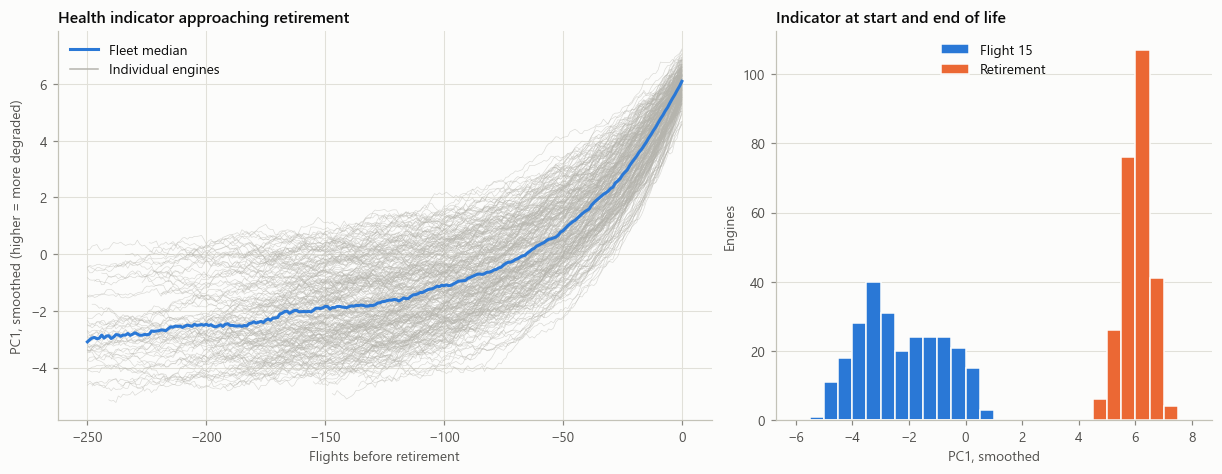

Flight 15: -2.26 ± 1.44
Retirement: 6.05 ± 0.48


In [11]:
z["health"] = scores[:, 0]
z["health_smooth"] = smooth(z, ["health"])["health"]

wide = z.pivot(index="RUL", columns="EngineID", values="health_smooth").loc[:250]
start = z.loc[z["Cycle"] == SMOOTH_FLIGHTS, "health_smooth"]
end = z.loc[z["RUL"] == 0, "health_smooth"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained", width_ratios=[1.5, 1])
ax = axes[0]
ax.plot(-wide.index, wide.to_numpy(), color=ENGINE_LINE, linewidth=0.4, alpha=0.5)
ax.plot(-wide.index, wide.median(axis=1), color=BLUE, linewidth=2, label="Fleet median")
ax.plot([], [], color=ENGINE_LINE, linewidth=1, label="Individual engines")
ax.set(title="Health indicator approaching retirement", xlabel="Flights before retirement", ylabel="PC1, smoothed (higher = more degraded)")
ax.legend(loc="upper left")

ax = axes[1]
bins = np.arange(np.floor(start.min()), np.ceil(end.max()) + 0.5, 0.5)
ax.hist(start, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1, label=f"Flight {SMOOTH_FLIGHTS}")
ax.hist(end, bins=bins, color=ORANGE, edgecolor=SURFACE, linewidth=1, label="Retirement")
ax.set(title="Indicator at start and end of life", xlabel="PC1, smoothed", ylabel="Engines")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center")
plt.show()

print(f"Flight {SMOOTH_FLIGHTS}: {start.mean():.2f} ± {start.std():.2f}")
print(f"Retirement: {end.mean():.2f} ± {end.std():.2f}")

## 9. Feature vectors by engine

These plots read the files saved by `features.ipynb`, so run that notebook first. Features start at flight 20, and `Cycle` is the x-axis here rather than its own panel. `plot_engines` works for any engine in any split.

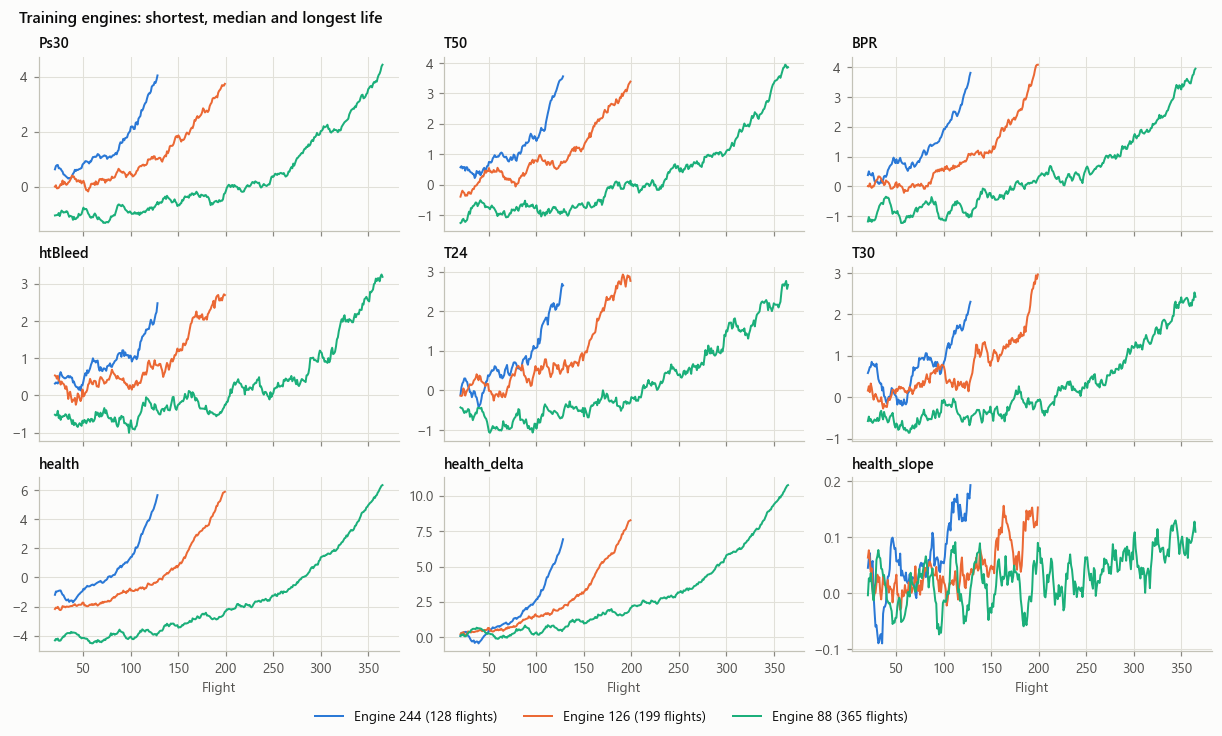

In [12]:
features = {split: pd.read_csv(f"Features/features_{split}.csv") for split in ["train", "val", "test"]}
labeled = pd.concat([features["train"], features["val"]], ignore_index=True)
derived = ["health", "health_delta", "health_slope"]
feature_panels = [c for c in features["train"].columns if c not in ("EngineID", "Cycle", "RUL")]
ENGINE_COLORS = [BLUE, ORANGE, "#1baf7a"]

def plot_engines(split, engine_ids, title):
    """Plot the feature vector over flights for up to three engines from one split."""
    table = features[split]
    fig, axes = plt.subplots(3, 3, figsize=(11, 6.6), sharex=True, layout="constrained")
    for ax, feature in zip(axes.flat, feature_panels):
        for engine_id, color in zip(engine_ids, ENGINE_COLORS):
            engine = table[table["EngineID"] == engine_id]
            ax.plot(engine["Cycle"], engine[feature], color=color, linewidth=1.3,
                    label=f"Engine {engine_id} ({engine['Cycle'].max()} flights)")
        ax.set_title(feature, fontsize=9.5)
    fig.suptitle(title, x=0.01, ha="left", fontsize=10.5, fontweight="semibold")
    for ax in axes[-1]:
        ax.set_xlabel("Flight")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncols=len(engine_ids))
    plt.show()

def shortest_median_longest(table):
    flights = table.groupby("EngineID")["Cycle"].max().sort_values()
    return [int(flights.index[i]) for i in (0, len(flights) // 2, -1)]

plot_engines("train", shortest_median_longest(features["train"]), "Training engines: shortest, median and longest life")

Validation engines were not used for any fitting, so these show how the features behave on unseen run-to-retirement engines.

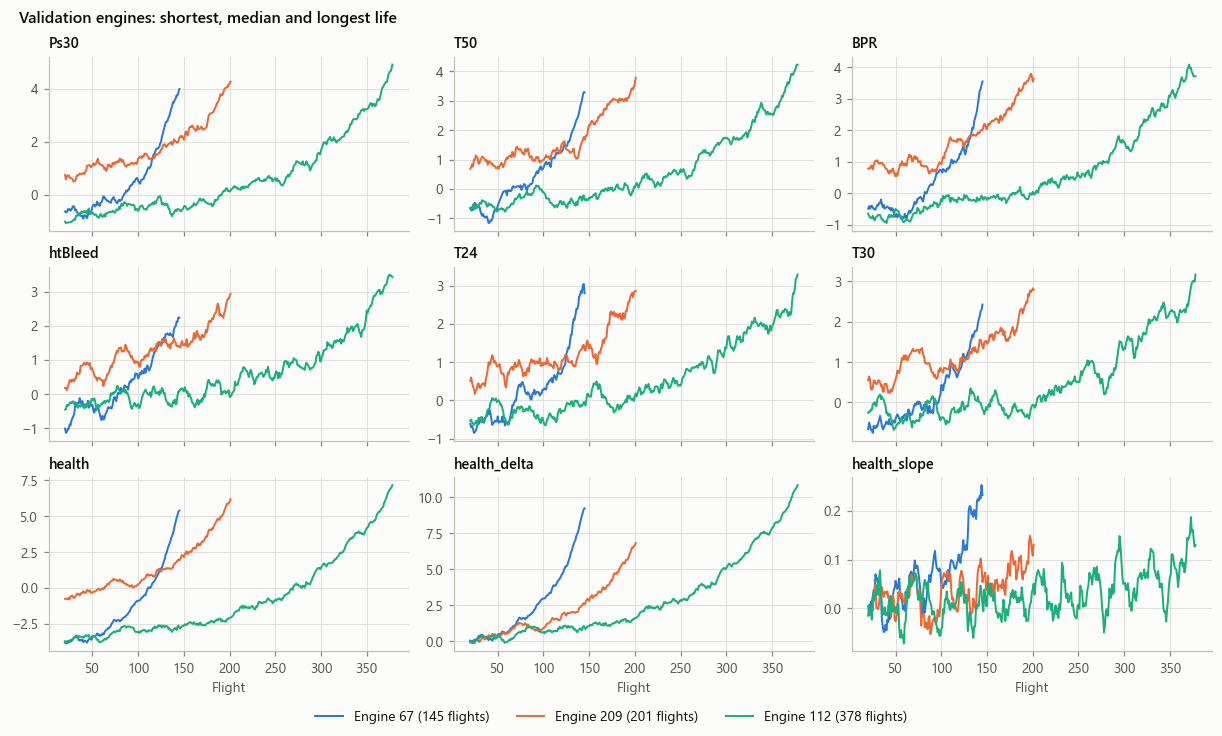

In [13]:
plot_engines("val", shortest_median_longest(features["val"]), "Validation engines: shortest, median and longest life")

Test engines stop before retirement, so these lines end mid-life. The engine with the fewest flights has only two feature rows (flights 20 and 21), so it appears as a short stub at the left of each panel.

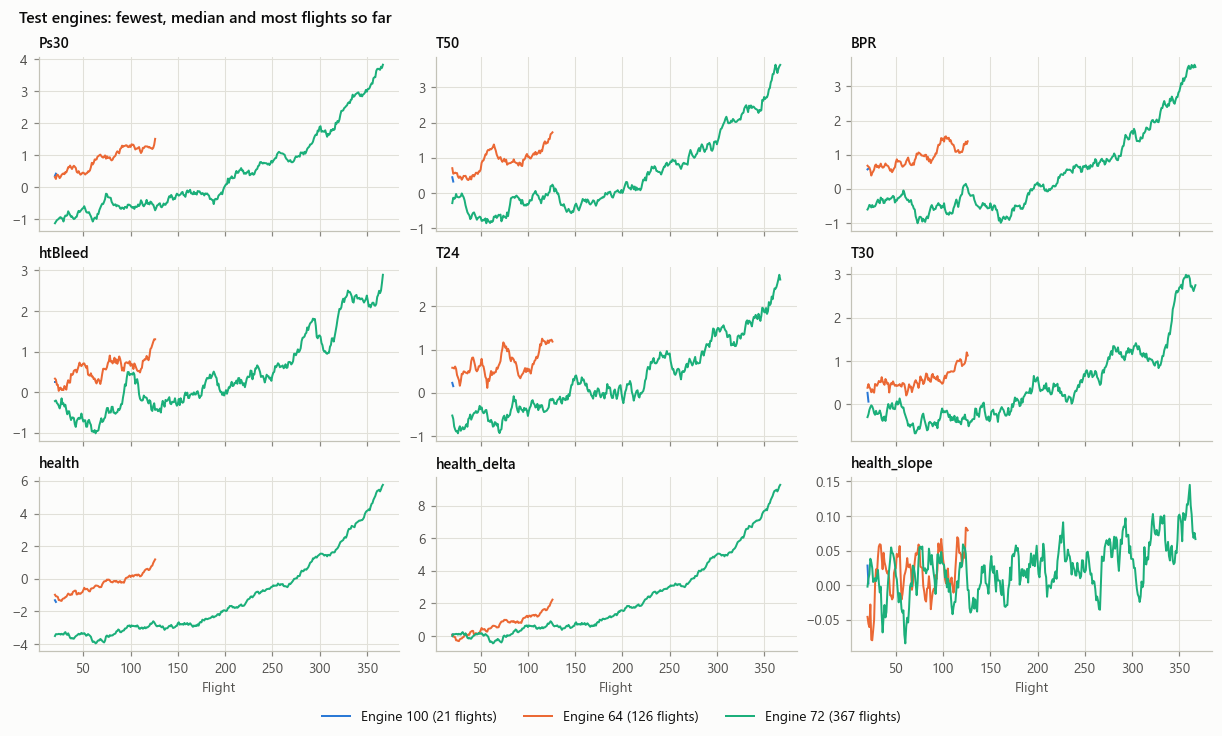

In [14]:
plot_engines("test", shortest_median_longest(features["test"]), "Test engines: fewest, median and most flights so far")

## 10. Derived features across all engines

Each grey line is one training or validation engine, aligned at retirement, and the blue line is the fleet median. A useful feature has a clear median trend and a band narrower than that trend.

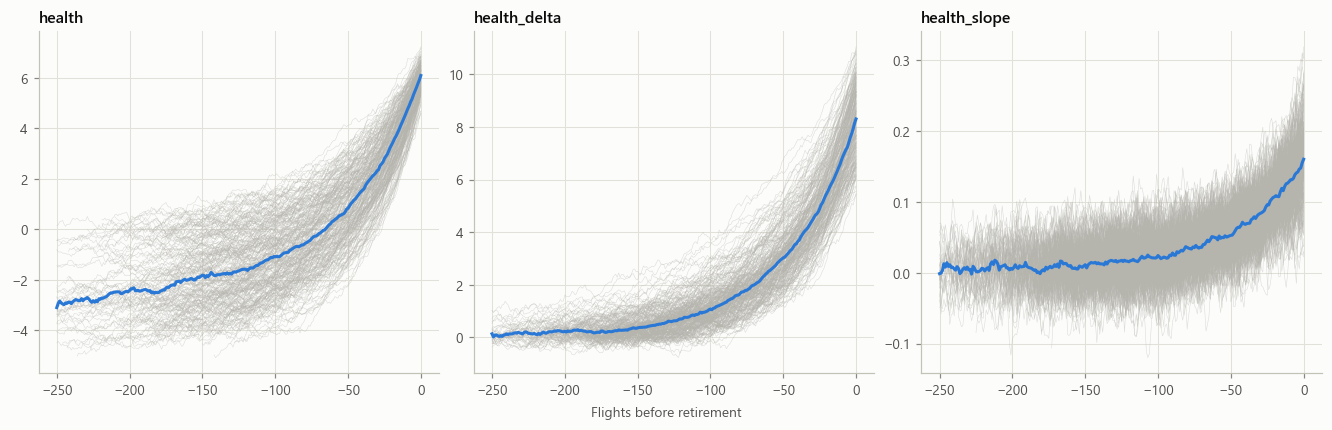

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, layout="constrained")
for ax, feature in zip(axes, derived):
    wide = labeled.assign(EngineKey=labeled["EngineID"]).pivot(index="RUL", columns="EngineKey", values=feature).loc[:250]
    ax.plot(-wide.index, wide.to_numpy(), color=ENGINE_LINE, linewidth=0.35, alpha=0.45)
    ax.plot(-wide.index, wide.median(axis=1), color=BLUE, linewidth=2)
    ax.set_title(feature)
fig.supxlabel("Flights before retirement", color=INK_2, fontsize=9)
plt.show()

## 11. Where the test engines sit

Each orange dot is one test engine at its last flight, which is the row a prediction is made from. The blue line and band show the training and validation fleet at the same flight count. Dots outside the band are degrading faster or slower than the fleet at that age. Fleet engines drop out as they retire, so the band at high flight counts only reflects the longest-lived engines.

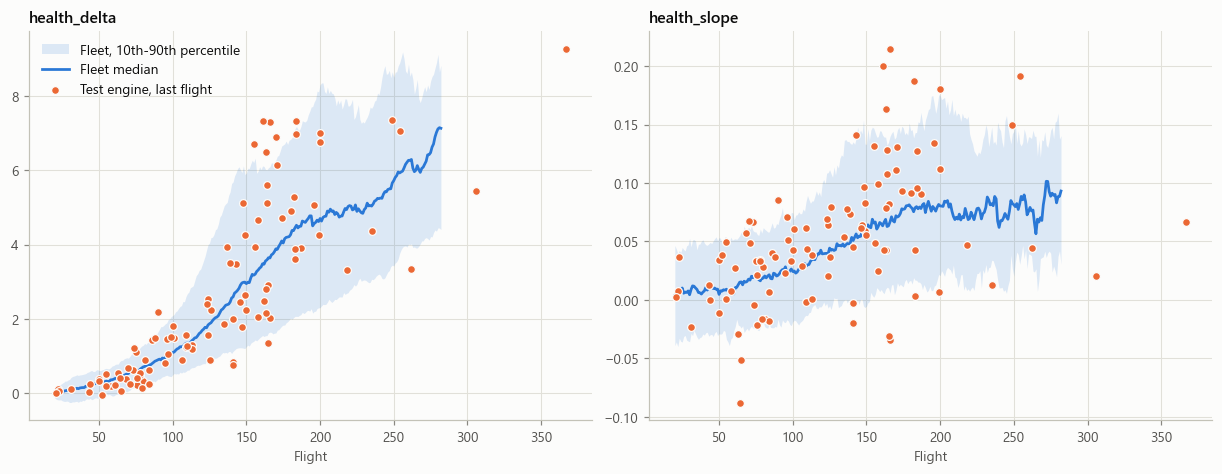

In [16]:
test_last = pd.read_csv("Features/features_test_last.csv")
enough = labeled.groupby("Cycle")["EngineID"].transform("size") >= 20   # hide flight counts with too few engines

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, layout="constrained")
for ax, feature in zip(axes, ["health_delta", "health_slope"]):
    fleet = labeled[enough].groupby("Cycle")[feature]
    ax.fill_between(fleet.median().index, fleet.quantile(0.1), fleet.quantile(0.9), color=BLUE, alpha=0.15, linewidth=0, label="Fleet, 10th-90th percentile")
    ax.plot(fleet.median().index, fleet.median(), color=BLUE, linewidth=1.8, label="Fleet median")
    ax.scatter(test_last["Cycle"], test_last[feature], s=26, color=ORANGE, edgecolor=SURFACE, linewidth=0.8, zorder=3, label="Test engine, last flight")
    ax.set(title=feature, xlabel="Flight")
axes[0].legend(loc="upper left")
plt.show()